# 05 — E1 so với E2: brand features có giúp mô hình không?
**Phụ trách: Phúc — tuần 5.** Notebook `05_advanced_models.ipynb` giải thích mô hình trên 12 URL features; notebook này lặp lại phép so sánh với 20 features của Hy.

- **E1**: 12 lexical features. **E2**: đúng 12 cột đó + 8 brand features; cùng ID, nhãn và folds.
- Chọn tham số bằng AP trong 2 inner domain folds; chấm bằng 3 outer folds của Hưng. Scaler luôn trong pipeline.
- Giữ nguyên grid/seed/quy tắc predict của notebook `05_advanced_models.ipynb`. Không sửa E1 đã khóa và không chấm Test.
- Reference của Hy hiện là **draft**, schema `e2-brand-v0`: kết quả E2 là **PRELIMINARY**, chưa phải bản freeze cuối.
- Run All sẽ train thật. Terminal: `python scripts/train_week5.py --ablation`.

## 1. Nạp thư viện và đặt đường dẫn
Đây là code sklearn trực tiếp; không gọi runner ML riêng. Chỉ giới hạn CPU để dễ tái lập trên máy local.

In [1]:
from pathlib import Path
import sys
import hashlib
import json
import platform
from datetime import datetime, timezone
from importlib.metadata import version
import warnings

import joblib
import nbformat
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             average_precision_score, confusion_matrix,
                             precision_recall_curve, ConfusionMatrixDisplay)
from threadpoolctl import threadpool_limits

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from phishguard_vn.splits import audit_domain_overlap
DATA = PROJECT_ROOT / "data/interim"
TABLES = PROJECT_ROOT / "reports/tables"
FIGURES = PROJECT_ROOT / "reports/figures"
MODELS_DIR = PROJECT_ROOT / "models"
for folder in [TABLES, FIGURES, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

from time import perf_counter
from io import BytesIO
import subprocess
from phishguard_vn.brand_features import (BRAND_FEATURES, E2_FEATURES, FEATURE_SCHEMA_VERSION,
                                         REFERENCE_PATH, load_reference)
from phishguard_vn.features import CANDIDATE_FEATURES

SEED = 42
PROTOCOL = "week5_e1_e2_readable_v1"
E1_FEATURES = list(CANDIDATE_FEATURES)
FEATURE_SETS = {"E1": E1_FEATURES, "E2": list(E2_FEATURES)}
CPU_LIMIT = threadpool_limits(limits=1)
print(PROJECT_ROOT, "|", PROTOCOL)


D:\PhishGuardVN | week5_e1_e2_readable_v1


## 2. Ghép dữ liệu bằng ID, kiểm tra E1–E2 giống mẫu
Trước khi chạy: `python scripts/05_build_matrix_x_brand.py --partition trainval`.
Chỉ đọc nhãn của Train/Validation; không tạo X_test/y_test. File domain cũ chỉ dùng cột ID/domain để kiểm tra split/folds.
Nếu thiếu ID/cột hoặc lexical values khác nhau thì dừng, không tự lấy giao để che mất mẫu.

In [2]:
core = pd.read_csv(DATA / "core_gold_silver.csv", dtype={"id": "string"}, low_memory=False)
# Loại Test trước khi kiểm tra nhãn, ghép X hay tính thống kê phục vụ mô hình.
core = core.loc[core["split"].isin(["train", "val"])].copy()
e1 = pd.read_csv(DATA / "03_matrix_X_features.csv", dtype={"id": "string"})
e1 = e1.loc[e1["id"].isin(core["id"])].copy()
e2 = pd.read_csv(DATA / "05_matrix_X_brand_trainval.csv", dtype={"id": "string"})
domains = pd.read_csv(DATA / "03_registrable_domains.csv", dtype={"id": "string"})
domains = domains.loc[domains["id"].isin(core["id"])].copy()
folds = pd.read_csv(DATA / "02_group_folds_train.csv", dtype={"id": "string"})
manifest_path = DATA / "05_matrix_X_brand_trainval.manifest.json"
feature_manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
reference = load_reference()

for frame in [core, e1, e2, domains, folds]:
    assert frame["id"].notna().all() and frame["id"].str.strip().ne("").all(), "ID thiếu/rỗng"
    assert frame["id"].is_unique, "ID trùng"
assert list(e1.columns) == ["id", *E1_FEATURES], "E1 sai schema"
assert list(e2.columns) == ["id", *FEATURE_SETS["E2"]], "E2 sai schema"
assert feature_manifest["partition"] == "trainval" and feature_manifest["test_excluded_from_this_artifact"]
assert feature_manifest["feature_schema_version"] == FEATURE_SCHEMA_VERSION
assert feature_manifest["columns"] == list(e2.columns)
assert feature_manifest["brand_reference"]["sha256"] == reference.sha256, "Reference đổi: chạy lại extractor"
assert feature_manifest["rows_x"] == len(e2)
assert feature_manifest["e1_columns_verified_identical_to_e1_matrix"]
assert set(e1["id"]) == set(e2["id"]), "E1/E2 khác tập mẫu"
assert np.isfinite(e2[FEATURE_SETS["E2"]].to_numpy(float)).all(), "NaN/Inf"
assert np.isfinite(e1[E1_FEATURES].to_numpy(float)).all()
a = e1.set_index("id")[E1_FEATURES].sort_index()
b = e2.set_index("id")[E1_FEATURES].sort_index()
np.testing.assert_allclose(a.to_numpy(float), b.to_numpy(float), rtol=0, atol=1e-9)
assert core["label"].isin(["benign", "phishing"]).all()
assert core["tier"].isin(["gold", "silver"]).all()
assert set(core["id"]) == set(domains["id"])
metadata = core[["id", "label", "tier", "split"]].merge(
    domains[["id", "registrable_domain"]], on="id", validate="one_to_one")
assert set(e2["id"]) == set(metadata.loc[metadata["registrable_domain"].notna(), "id"])
assert audit_domain_overlap(metadata)["status"] != "overlap_detected"
assert list(folds.columns) == ["id", "fold_id"]
assert pd.api.types.is_integer_dtype(folds["fold_id"])
assert set(folds["fold_id"]) == {0, 1, 2}
assert set(folds["id"]) == set(metadata.loc[
    metadata["split"].eq("train") & metadata["registrable_domain"].notna(), "id"])

eligible = e2.merge(metadata, on="id", validate="one_to_one")
train = eligible.loc[eligible["split"].eq("train")].merge(
    folds, on="id", validate="one_to_one").sort_values("id").reset_index(drop=True)
validation = eligible.loc[eligible["split"].eq("val")].sort_values("id").reset_index(drop=True)
for frame in [train, validation]:
    frame["target"] = frame["label"].map({"benign": 0, "phishing": 1})
    assert frame["target"].nunique() == 2
assert train.groupby("registrable_domain")["fold_id"].nunique().eq(1).all()
assert set(train["registrable_domain"]).isdisjoint(validation["registrable_domain"])
print("Train:", len(train), "| Validation:", len(validation), "| Reference:", reference.summary())
display(train.groupby(["fold_id", "label"]).size().unstack(fill_value=0))


Train: 13078 | Validation: 1585 | Reference: {'file': 'brand_reference_v1.csv', 'sha256': 'b40f66bbad8327d1e022a5dcb8869ad7ee4a6f46bcfea48ccec20545a91d50bd', 'n_brands': 37, 'status_counts': {'draft': 37}, 'n_missing_source_accessed': 37, 'n_missing_source_url': 0, 'fully_verified': False, 'n_brands_with_official_suffixes': 0, 'n_brands_with_typo_ignore': 0}


label,benign,phishing
fold_id,,
0,3668,691
1,3668,691
2,3668,692


## 3. Mô hình và grid — giữ như notebook `05_advanced_models.ipynb`
Năm cấu hình thuộc bốn họ LR/SVM/MLP/HistGB. Grid chỉ hai cấu hình mỗi họ có tuning. Mỗi lần E1/E2 đều tạo model mới bằng `clone`; không dùng model đã học của nhánh kia.

**Quy tắc shortlist chốt trước khi xem kết quả:** trong mỗi họ lấy feature set có mean outer AP cao nhất; hòa thì F1 cao, FPR thấp, E1 trước. Xếp các họ theo cùng AP/F1/FPR và chọn tối đa hai họ khác nhau. Validation chỉ báo cáo bổ sung, không tham gia lựa chọn. Đây là ứng viên Teacher, chưa chưng cất KD hay đánh giá cuối.

In [3]:
lr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(C=1.0, max_iter=2000, random_state=SEED))
])
lr_balanced = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000, random_state=SEED))
])
svm = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(kernel="rbf", gamma="scale", cache_size=256))
])
mlp = Pipeline([
    ("scaler", StandardScaler()),
    ("model", MLPClassifier(alpha=0.001, max_iter=1000, batch_size=256,
                            early_stopping=False, n_iter_no_change=20, random_state=SEED))
])
boosting = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.1,
                                        l2_regularization=1.0, early_stopping=False,
                                        random_state=SEED)

models = {"logistic_regression": lr, "logistic_regression_balanced": lr_balanced,
          "svm_rbf": svm, "mlp": mlp, "hist_gradient_boosting": boosting}
# Chỉ thử hai cấu hình mỗi họ; không thêm grid vì nhìn validation/test.
param_grids = {"logistic_regression": {}, "logistic_regression_balanced": {},
               "svm_rbf": {"model__C": [0.5, 2.0]},
               "mlp": {"model__hidden_layer_sizes": [(32,), (32, 16)]},
               "hist_gradient_boosting": {"max_leaf_nodes": [7, 15]}}


## 4. Lưu phân hoạch học/chấm để Hưng đối chiếu
Outer folds giữ nguyên từ Hưng. Với mỗi outer fold, tạo 2 inner domain folds **chỉ trong phần fitting**. E1/E2 dùng đúng cùng phân hoạch này, không tính lại theo feature.
`full_train` chỉ dùng khi fit model cuối trên toàn Train. Bảng partitions ghi rõ mẫu nào fitting, mẫu nào held-out, mẫu fitting thuộc inner fold nào; không có Validation/Test trong bảng này.

In [4]:
inner_splits_by_context, partition_tables = {}, []
for context in [0, 1, 2, "full_train"]:
    fitting = train if context == "full_train" else train.loc[train["fold_id"].ne(context)]
    held_out = train.iloc[:0] if context == "full_train" else train.loc[train["fold_id"].eq(context)]
    assert set(fitting["id"]).isdisjoint(held_out["id"])
    assert set(fitting["registrable_domain"]).isdisjoint(held_out["registrable_domain"])
    splitter = StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=SEED)
    splits = list(splitter.split(fitting[E1_FEATURES], fitting["target"], fitting["registrable_domain"]))
    inner_splits_by_context[context] = splits
    assignments = pd.DataFrame({"id": fitting["id"].to_numpy(), "context": str(context),
                                "role": "fitting", "inner_fold_id": -1})
    for inner_id, (fit_index, score_index) in enumerate(splits):
        assert fitting.iloc[fit_index]["target"].nunique() == fitting.iloc[score_index]["target"].nunique() == 2
        assert set(fitting.iloc[fit_index]["registrable_domain"]).isdisjoint(
            fitting.iloc[score_index]["registrable_domain"])
        assignments.loc[score_index, "inner_fold_id"] = inner_id
    assert assignments["inner_fold_id"].ge(0).all()
    partition_tables.append(assignments)
    partition_tables.append(pd.DataFrame({"id": held_out["id"].to_numpy(), "context": str(context),
                                          "role": "held_out", "inner_fold_id": -1}))
training_partitions = pd.concat(partition_tables, ignore_index=True)
display(training_partitions.groupby(["context", "role"]).size().rename("rows"))


context     role    
0           fitting      8719
            held_out     4359
1           fitting      8719
            held_out     4359
2           fitting      8718
            held_out     4360
full_train  fitting     13078
Name: rows, dtype: int64

## 5. Hàm chấm điểm
AP chấp nhận cả probability và margin. Nhãn luôn lấy từ `.predict()`: SVM dùng ranh giới margin 0, các model khác dùng xác suất 0,5. Không hiệu chỉnh threshold.

In [5]:
def calculate_metrics(y_true, predicted, score):
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(y_true, predicted),
            "precision_phishing": precision_score(y_true, predicted, zero_division=0),
            "recall_phishing": recall_score(y_true, predicted, zero_division=0),
            "f1_phishing": f1_score(y_true, predicted, zero_division=0),
            "pr_auc": average_precision_score(y_true, score),
            "false_positive_rate": fp / (fp + tn),
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}


## 6. Train và predict từng outer fold — đây là OOF
Thêm vòng lặp E1/E2 bên ngoài luồng của notebook `05_advanced_models.ipynb`. `GridSearchCV.fit` chỉ nhận các mẫu fitting; kết quả `best_estimator_` đã refit trên phần fitting đó, rồi mới predict held-out.
OOF nghĩa là mỗi mẫu Train chỉ được dự đoán bởi model không học mẫu/domain đó. Lưu cả nhãn, score, loại score, candidate và fold để Hưng kiểm tra.

In [6]:
cv_rows, prediction_tables, parameter_rows = [], [], []
for feature_set, feature_names in FEATURE_SETS.items():
    for model_name, model in models.items():
        candidate = f"{feature_set}__{model_name}"
        for fold_id in [0, 1, 2]:
            fitting = train.loc[train["fold_id"].ne(fold_id)]
            held_out = train.loc[train["fold_id"].eq(fold_id)]
            X_train, y_train = fitting[feature_names], fitting["target"]
            X_holdout, y_holdout = held_out[feature_names], held_out["target"]
            with warnings.catch_warnings():
                warnings.simplefilter("error", ConvergenceWarning)
                if param_grids[model_name]:
                    search = GridSearchCV(clone(model), param_grids[model_name],
                                          scoring="average_precision", cv=inner_splits_by_context[fold_id],
                                          n_jobs=1, error_score="raise", refit=True)
                    search.fit(X_train, y_train)
                    fitted_model, best_params = search.best_estimator_, search.best_params_
                else:
                    fitted_model = clone(model)
                    fitted_model.fit(X_train, y_train)
                    best_params = {}
            predicted = fitted_model.predict(X_holdout)
            if model_name == "svm_rbf":
                score, score_kind = fitted_model.decision_function(X_holdout), "decision_function"
            else:
                score, score_kind = fitted_model.predict_proba(X_holdout)[:, 1], "probability"
            assert list(fitted_model.classes_) == [0, 1] and np.isfinite(score).all()
            cv_rows.append({"candidate": candidate, "feature_set": feature_set, "model": model_name,
                            "fold_id": fold_id, **calculate_metrics(y_holdout, predicted, score)})
            prediction_tables.append(pd.DataFrame({
                "id": held_out["id"].to_numpy(), "candidate": candidate, "feature_set": feature_set,
                "model": model_name, "fold_id": fold_id, "evaluation_partition": "group_cv",
                "true_label": y_holdout.to_numpy(), "predicted_label": predicted,
                "score": score, "score_kind": score_kind, "decision_rule": "estimator.predict"}))
            parameter_rows.append({"candidate": candidate, "context": str(fold_id),
                                   "parameters": json.dumps(best_params, sort_keys=True)})
            print(candidate, "fold", fold_id, "AP =", round(cv_rows[-1]["pr_auc"], 4), flush=True)
cv_metrics = pd.DataFrame(cv_rows)
cv_predictions = pd.concat(prediction_tables, ignore_index=True)
assert not cv_predictions.duplicated(["candidate", "id"]).any()
assert cv_predictions.groupby("candidate").size().eq(len(train)).all()
assert set(cv_predictions["id"]) == set(train["id"])


E1__logistic_regression fold 0 AP = 0.6123


E1__logistic_regression fold 1 AP = 0.5833


E1__logistic_regression fold 2 AP = 0.5869


E1__logistic_regression_balanced fold 0 AP = 0.5587


E1__logistic_regression_balanced fold 1 AP = 0.5418


E1__logistic_regression_balanced fold 2 AP = 0.5727


... (21 outputs left out)

E2__mlp fold 2 AP = 0.7482


E2__hist_gradient_boosting fold 0 AP = 0.7261


E2__hist_gradient_boosting fold 1 AP = 0.7376


E2__hist_gradient_boosting fold 2 AP = 0.7035


## 7. Delta và độ ổn định theo fold; shortlist
Delta = E2 − E1 **trong cùng fold/cùng họ**. AP/F1/Recall tăng là tốt; FPR tăng là xấu. Mean/std/min/max của ba delta mô tả độ ổn định; **không phải confidence interval**. Chỉ ba folds, cùng nguồn dữ liệu và có thử nhiều cấu hình nên không kết luận cải thiện có ý nghĩa thống kê hay hiệu quả ngoài thực tế.

AP dùng chọn ứng viên là mean AP của ba folds. Pooled OOF chỉ minh họa: các fold, đặc biệt SVM, có thể có thang score khác nhau. Giữ bảng mọi cấu hình kể cả E2 kém hơn E1.

In [7]:
metric_names = ["pr_auc", "precision_phishing", "recall_phishing", "f1_phishing", "false_positive_rate"]
summary = cv_metrics.groupby(["candidate", "feature_set", "model"])[metric_names].agg(["mean", "std"])
summary.columns = [f"{metric}_{stat}" for metric, stat in summary.columns]
summary = summary.reset_index().sort_values(
    ["pr_auc_mean", "f1_phishing_mean", "false_positive_rate_mean", "candidate"],
    ascending=[False, False, True, True]).reset_index(drop=True)
left = cv_metrics.loc[cv_metrics.feature_set.eq("E1"), ["model", "fold_id", *metric_names]]
right = cv_metrics.loc[cv_metrics.feature_set.eq("E2"), ["model", "fold_id", *metric_names]]
paired = left.merge(right, on=["model", "fold_id"], suffixes=("_e1", "_e2"), validate="one_to_one")
for metric in metric_names:
    paired[f"delta_{metric}"] = paired[f"{metric}_e2"] - paired[f"{metric}_e1"]
delta_names = [f"delta_{metric}" for metric in metric_names]
deltas = paired.groupby("model")[delta_names].agg(["mean", "std", "min", "max"])
deltas.columns = [f"{metric}_{stat}" for metric, stat in deltas.columns]
deltas = deltas.reset_index()
# LR standard/balanced là cùng một họ: không chiếm hai chỗ trong shortlist.
summary["family"] = summary["model"].replace({"logistic_regression_balanced": "logistic_regression"})
shortlist = summary.drop_duplicates("family").head(2).copy()
selected_candidate = shortlist.iloc[0]["candidate"]
display(summary)
display(deltas)
print("Shortlist (Train Group CV, chưa dùng Validation):", shortlist["candidate"].tolist())


,candidate,feature_set,model,pr_auc_mean,pr_auc_std,precision_phishing_mean,precision_phishing_std,recall_phishing_mean,recall_phishing_std,f1_phishing_mean,f1_phishing_std,false_positive_rate_mean,false_positive_rate_std,family
0,E2__mlp,E2,mlp,0.733483,0.014156,0.844134,0.014175,0.504825,0.020648,0.631507,0.013037,0.017630,0.002533,mlp
1,E2__hist_gradient_boosting,E2,hist_gradient_boosting,0.722418,0.017338,0.831731,0.011307,0.503875,0.034679,0.627211,0.029556,0.019175,0.001102,hist_gradient_boosting
2,E1__mlp,E1,mlp,0.699200,0.014049,0.798302,0.024278,0.481222,0.048225,0.598947,0.033277,0.023173,0.005308,mlp
3,E1__hist_gradient_boosting,E1,hist_gradient_boosting,0.697899,0.022626,0.819157,0.003361,0.482176,0.032179,0.606561,0.024645,0.020084,0.001774,hist_gradient_boosting
4,E2__svm_rbf,E2,svm_rbf,0.654465,0.042049,0.849417,0.045969,0.459495,0.006294,0.596134,0.014087,0.015540,0.005567,svm_rbf
5,E1__svm_rbf,E1,svm_rbf,0.642641,0.031806,0.845691,0.037716,0.418524,0.018516,0.559552,0.016935,0.014540,0.004365,svm_rbf
6,E2__logistic_regression,E2,logistic_regression,0.641664,0.004639,0.754533,0.022503,0.368385,0.027165,0.494414,0.022551,0.022719,0.003868,logistic_regression
7,E2__logistic_regression_balanced,E2,logistic_regression_balanced,0.630600,0.012427,0.432879,0.029227,0.734319,0.019956,0.543913,0.018246,0.182752,0.027847,logistic_regression
8,E1__logistic_regression,E1,logistic_regression,0.594173,0.015811,0.729997,0.029375,0.326929,0.045412,0.449986,0.043073,0.022992,0.005331,logistic_regression
9,E1__logistic_regression_balanced,E1,logistic_regression_balanced,0.557744,0.015502,0.344914,0.012513,0.807131,0.008863,0.483148,0.010705,0.289440,0.019357,logistic_regression


,model,delta_pr_auc_mean,delta_pr_auc_std,delta_pr_auc_min,delta_pr_auc_max,delta_precision_phishing_mean,delta_precision_phishing_std,delta_precision_phishing_min,delta_precision_phishing_max,delta_recall_phishing_mean,...,delta_recall_phishing_min,delta_recall_phishing_max,delta_f1_phishing_mean,delta_f1_phishing_std,delta_f1_phishing_min,delta_f1_phishing_max,delta_false_positive_rate_mean,delta_false_positive_rate_std,delta_false_positive_rate_min,delta_false_positive_rate_max
0,hist_gradient_boosting,0.024518,0.006266,0.019123,0.031392,0.012574,0.013980,0.003336,0.028657,0.021699,...,0.017341,0.026049,0.020650,0.004971,0.015183,0.024897,-0.000909,0.002046,-0.003272,0.000273
1,logistic_regression,0.047491,0.014508,0.031004,0.058307,0.024536,0.010336,0.013620,0.034172,0.041456,...,0.027496,0.062139,0.044428,0.020675,0.027432,0.067446,-0.000273,0.001518,-0.001908,0.001091
2,logistic_regression_balanced,0.072856,0.004675,0.069028,0.078066,0.087966,0.018255,0.066950,0.099897,-0.072813,...,-0.081042,-0.059249,0.060765,0.009295,0.050412,0.068392,-0.106688,0.012012,-0.118321,-0.094329
3,mlp,0.034283,0.021881,0.016887,0.058849,0.045831,0.020254,0.033833,0.069215,0.023603,...,-0.011577,0.070809,0.032561,0.030578,0.010996,0.067555,-0.005543,0.004432,-0.010360,-0.001636
4,svm_rbf,0.011824,0.010311,0.001831,0.022426,0.003726,0.023418,-0.016045,0.029588,0.040971,...,0.020260,0.067919,0.036583,0.027367,0.012721,0.066455,0.001000,0.002046,-0.001091,0.002999


Shortlist (Train Group CV, chưa dùng Validation): ['E2__mlp', 'E2__hist_gradient_boosting']


## 8. Fit model cuối trên toàn Train, rồi chấm Validation bổ sung
Lại chọn tham số bằng 2 inner domain folds chỉ trong Train. Lưu mười model để tái lập so sánh; shortlist đã chốt ở cell trên. Không đưa Validation vào fit và không đổi lựa chọn theo kết quả Validation.
Bundle E2 giữ snapshot reference thực dùng, schema và hash code extractor để dự đoán URL mới đúng công thức đã train. E1 cũ vẫn load được.

In [8]:
trained_models, validation_rows, validation_tables, bundles = {}, [], [], {}
extractor_files = ["features.py", "url_parser.py", "brand_features.py"]
extractor_hashes = {name: hashlib.sha256((PROJECT_ROOT / "src/phishguard_vn" / name).read_bytes().replace(b"\r\n", b"\n")).hexdigest()
                    for name in extractor_files}
for feature_set, feature_names in FEATURE_SETS.items():
    family_models = {}
    for model_name, model in models.items():
        candidate = f"{feature_set}__{model_name}"
        with warnings.catch_warnings():
            warnings.simplefilter("error", ConvergenceWarning)
            if param_grids[model_name]:
                search = GridSearchCV(clone(model), param_grids[model_name], scoring="average_precision",
                                      cv=inner_splits_by_context["full_train"], n_jobs=1, error_score="raise", refit=True)
                search.fit(train[feature_names], train["target"])
                fitted_model, best_params = search.best_estimator_, search.best_params_
            else:
                fitted_model = clone(model)
                fitted_model.fit(train[feature_names], train["target"])
                best_params = {}
        assert list(fitted_model.classes_) == [0, 1]
        family_models[model_name] = fitted_model
        trained_models[candidate] = fitted_model
        parameter_rows.append({"candidate": candidate, "context": "full_train",
                               "parameters": json.dumps(best_params, sort_keys=True)})
        predicted = fitted_model.predict(validation[feature_names])
        if model_name == "svm_rbf":
            score, score_kind = fitted_model.decision_function(validation[feature_names]), "decision_function"
        else:
            score, score_kind = fitted_model.predict_proba(validation[feature_names])[:, 1], "probability"
        assert np.isfinite(score).all()
        validation_rows.append({"candidate": candidate, "feature_set": feature_set, "model": model_name,
                                **calculate_metrics(validation["target"], predicted, score)})
        validation_tables.append(pd.DataFrame({
            "id": validation["id"].to_numpy(), "candidate": candidate, "feature_set": feature_set,
            "model": model_name, "evaluation_partition": "official_validation",
            "true_label": validation["target"].to_numpy(), "predicted_label": predicted,
            "score": score, "score_kind": score_kind, "decision_rule": "estimator.predict"}))
    winner = summary.loc[summary.feature_set.eq(feature_set)].iloc[0]["model"]
    bundles[feature_set] = {"models": family_models, "selected_model": winner, "feature_names": feature_names,
                           "feature_set": "lexical_12" if feature_set == "E1" else FEATURE_SCHEMA_VERSION,
                           "score_kinds": {name: "decision_function" if name == "svm_rbf" else "probability" for name in models},
                           "protocol": PROTOCOL, "decision_rule": "estimator.predict"}
    if feature_set == "E2":
        bundles[feature_set].update(brand_reference=reference, extractor_source_sha256=extractor_hashes)
validation_metrics = pd.DataFrame(validation_rows)
validation_predictions = pd.concat(validation_tables, ignore_index=True)
display(validation_metrics)


,candidate,feature_set,model,accuracy,precision_phishing,recall_phishing,f1_phishing,pr_auc,false_positive_rate,tn,fp,fn,tp
0,E1__logistic_regression,E1,logistic_regression,0.970347,0.255319,0.500000,0.338028,0.293308,0.022422,1526,35,12,12
1,E1__logistic_regression_balanced,E1,logistic_regression_balanced,0.591798,0.034380,0.958333,0.066378,0.274431,0.413837,915,646,1,23
2,E1__svm_rbf,E1,svm_rbf,0.980442,0.360000,0.375000,0.367347,0.263879,0.010250,1545,16,15,9
3,E1__mlp,E1,mlp,0.969085,0.244898,0.500000,0.328767,0.431387,0.023703,1524,37,12,12
4,E1__hist_gradient_boosting,E1,hist_gradient_boosting,0.976025,0.325000,0.541667,0.406250,0.433845,0.017297,1534,27,11,13
5,E2__logistic_regression,E2,logistic_regression,0.972871,0.288889,0.541667,0.376812,0.349303,0.020500,1529,32,11,13
6,E2__logistic_regression_balanced,E2,logistic_regression_balanced,0.747634,0.054502,0.958333,0.103139,0.309782,0.255605,1162,399,1,23
7,E2__svm_rbf,E2,svm_rbf,0.978549,0.352941,0.500000,0.413793,0.244515,0.014094,1539,22,12,12
8,E2__mlp,E2,mlp,0.973502,0.295455,0.541667,0.382353,0.376247,0.019859,1530,31,11,13
9,E2__hist_gradient_boosting,E2,hist_gradient_boosting,0.979180,0.378378,0.583333,0.459016,0.427817,0.014734,1538,23,10,14


## 9. Brand contribution và các mẫu thay đổi dự đoán
So sánh cả nhóm tám features bằng E1/E2, không quy tác dụng cho riêng một cột có tương quan. Chia thêm OOF thành nhóm có/không có tín hiệu brand để thấy độ phủ; đây là phân tích mô tả, không dùng chọn feature/threshold.
Chọn tối đa hai mẫu cải thiện và hai mẫu xấu đi mỗi fold/họ shortlisted. URL được vô hiệu hóa khi hiển thị. Các ghi chú tự động chỉ mô tả dự đoán/feature, không phải người đã xác minh nhãn/website.

Brand signal trên Train: 578 / 13078


,model,fold_id,change,rows
0,hist_gradient_boosting,0,improved,40
1,hist_gradient_boosting,0,unchanged,4296
2,hist_gradient_boosting,0,worsened,23
3,hist_gradient_boosting,1,improved,45
4,hist_gradient_boosting,1,unchanged,4296
5,hist_gradient_boosting,1,worsened,18
6,hist_gradient_boosting,2,improved,26
7,hist_gradient_boosting,2,unchanged,4319
8,hist_gradient_boosting,2,worsened,15
9,logistic_regression,0,improved,42


,id,model,fold_id,change,url,observation,brand_in_domain,brand_in_subdomain,brand_in_path,brand_domain_mismatch,brand_typo_score,susp_token_cnt,idna_flag,homoglyph_brand_hit
0,00f4afa6-d2b5-5e4f-b30e-c448d4fb2cbf,mlp,1,improved,https://www[.]binhthuan[.]dcs[.]vn,E1=1; E2=0; dataset label=0; improved,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,01771155-1859-5fbe-8486-9cea08579118,mlp,0,improved,vn-7v[.]vip,E1=0; E2=1; dataset label=1; improved,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,01771155-1859-5fbe-8486-9cea08579118,hist_gradient_boosting,0,worsened,vn-7v[.]vip,E1=1; E2=0; dataset label=1; worsened,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0275e074-bc91-5f20-bb5f-f2f453c257dc,mlp,2,worsened,11478[.]com,E1=0; E2=1; dataset label=0; worsened,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,02f47214-b2e0-5096-9dcf-92dede2e3b58,mlp,1,worsened,sevenbank-soukin-vietnam[.]weebly[.]com,E1=1; E2=0; dataset label=1; worsened,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,03b40176-8256-562b-a496-2764921e6108,hist_gradient_boosting,1,improved,quatangshopeevn[.]com,E1=0; E2=1; dataset label=1; improved,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
6,03b40176-8256-562b-a496-2764921e6108,mlp,1,improved,quatangshopeevn[.]com,E1=0; E2=1; dataset label=1; improved,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
7,03d40625-c216-5630-bb08-c47c30b6940d,hist_gradient_boosting,1,worsened,vnptdanang24h[.]online,E1=1; E2=0; dataset label=1; worsened,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,03f31f69-6869-51f4-afbf-e0da948813d8,mlp,2,improved,nganhangagribank[.]vn,E1=0; E2=1; dataset label=1; improved,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
9,043a298e-278f-5149-8d2a-41d0f005aa2b,mlp,1,worsened,vnpayment[.]vn,E1=0; E2=1; dataset label=0; worsened,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0


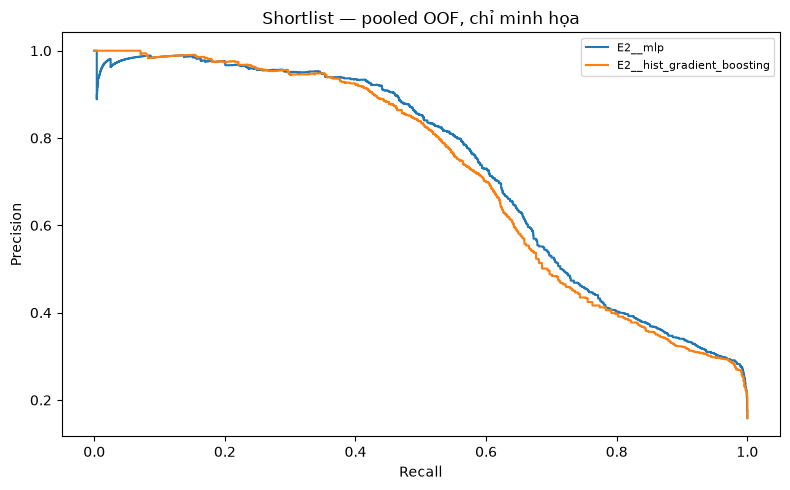

In [9]:
p1 = cv_predictions.loc[cv_predictions.feature_set.eq("E1")]
p2 = cv_predictions.loc[cv_predictions.feature_set.eq("E2")]
changes = p1.merge(p2, on=["id", "model", "fold_id", "true_label"], suffixes=("_e1", "_e2"), validate="one_to_one")
changes["e1_correct"] = changes.predicted_label_e1.eq(changes.true_label)
changes["e2_correct"] = changes.predicted_label_e2.eq(changes.true_label)
changes["change"] = np.select([~changes.e1_correct & changes.e2_correct,
                                changes.e1_correct & ~changes.e2_correct], ["improved", "worsened"], default="unchanged")
change_counts = changes.groupby(["model", "fold_id", "change"]).size().rename("rows").reset_index()
shortlisted_models = set(shortlist["model"])
examples = changes.loc[changes.model.isin(shortlisted_models) & changes.change.ne("unchanged")]
examples = examples.sort_values("id").groupby(["model", "fold_id", "change"]).head(2)
examples = examples.merge(core[["id", "url", "source", "tier"]], on="id", validate="many_to_one")
examples = examples.merge(train[["id", *BRAND_FEATURES]], on="id", validate="many_to_one")
examples["url"] = examples["url"].str.replace(".", "[.]", regex=False)
examples["observation"] = examples.apply(lambda r: f"E1={r.predicted_label_e1}; E2={r.predicted_label_e2}; dataset label={r.true_label}; {r.change}", axis=1)
examples["hypothesis"] = "Thêm nhóm brand và refit có thể thay đổi ranh giới; chưa tách nguyên nhân từng feature."
examples["next_check"] = "Hưng đối chiếu URL/features và nhãn gốc; Hy rà rule/reference nếu có false match; không sửa rule theo Validation/Test."

coverage = train[["id"]].copy()
coverage["brand_signal"] = train[list(BRAND_FEATURES)].ne(0).any(axis=1)
subgroup_rows = []
for keys, rows in cv_predictions.merge(coverage, on="id", validate="many_to_one").groupby(["candidate", "brand_signal"]):
    if rows.true_label.nunique() == 2:
        subgroup_rows.append({"candidate": keys[0], "brand_signal": keys[1], "rows": len(rows),
                              **calculate_metrics(rows.true_label, rows.predicted_label, rows.score)})
subgroup_metrics = pd.DataFrame(subgroup_rows)
print("Brand signal trên Train:", int(coverage.brand_signal.sum()), "/", len(train))
display(change_counts)
display(examples[["id", "model", "fold_id", "change", "url", "observation", *BRAND_FEATURES]])

fig, ax = plt.subplots(figsize=(8, 5))
for candidate in shortlist["candidate"]:
    rows = cv_predictions.loc[cv_predictions.candidate.eq(candidate)]
    precision, recall, _ = precision_recall_curve(rows.true_label, rows.score)
    ax.step(recall, precision, where="post", label=candidate)
ax.set(xlabel="Recall", ylabel="Precision", title="Shortlist — pooled OOF, chỉ minh họa")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "06_ablation_pr.png", dpi=140)
plt.show()


## 10. Kích thước và latency PC của shortlist
Dùng model đã fit trên toàn Train: 5 lượt warm-up, 30 lượt đo trên batch 1 và 128. Tính cả `.predict()` và score, chưa gồm trích feature/network/UI. Kích thước là pipeline serialized không nén; E2 bundle còn chứa reference. Đây là đo PC, không suy ra tốc độ mobile hay lợi ích KD.

In [10]:
resource_rows = []
for row in shortlist.itertuples():
    fitted_model = trained_models[row.candidate]
    stream = BytesIO()
    joblib.dump(fitted_model, stream)
    for batch_size in [1, 128]:
        sample = train[FEATURE_SETS[row.feature_set]].iloc[:batch_size]
        durations = []
        for repeat in range(35):
            start = perf_counter()
            fitted_model.predict(sample)
            if row.model == "svm_rbf":
                fitted_model.decision_function(sample)
            else:
                fitted_model.predict_proba(sample)
            if repeat >= 5:
                durations.append((perf_counter() - start) * 1000)
        resource_rows.append({"candidate": row.candidate, "batch_size": batch_size,
                              "serialized_pipeline_bytes": stream.tell(), "repeats": 30, "warmups": 5,
                              "latency_p50_ms": float(np.median(durations)),
                              "latency_p95_ms": float(np.quantile(durations, 0.95)),
                              "scope": "PC predict + score; precomputed features; CPU threads=1"})
resources = pd.DataFrame(resource_rows)
display(resources)


,candidate,batch_size,serialized_pipeline_bytes,repeats,warmups,latency_p50_ms,latency_p95_ms,scope
0,E2__mlp,1,38225,30,5,1.81215,2.327110,PC predict + score; precomputed features; CPU ...
1,E2__mlp,128,38225,30,5,2.26485,2.595610,PC predict + score; precomputed features; CPU ...
2,E2__hist_gradient_boosting,1,146992,30,5,2.53825,3.941920,PC predict + score; precomputed features; CPU ...
3,E2__hist_gradient_boosting,128,146992,30,5,4.68885,5.608265,PC predict + score; precomputed features; CPU ...


## 11. Lưu kết quả và ba bảng bàn giao
Prefix `06_*` tách với kết quả E1 cũ. Hưng nhận ba bảng `.csv.gz` ngay trong `reports/tables/`: OOF, Validation và training partitions. `pd.read_csv` đọc trực tiếp, không cần giải nén. Model giữ ở local; code và reference có trong repo. **Không có mẫu Test**. Metadata ghi HEAD và trạng thái dirty thật tại lúc chạy; không dùng commit cũ để giả là code hiện tại đã commit.
Raw reference hash có thể khác giữa LF/CRLF trên hai máy; ghi thêm hash sau chuẩn hóa LF để Hưng đối chiếu nội dung. Không tự đổi reference từ draft thành verified.

In [ ]:
tables = {"cv_metrics": cv_metrics, "comparison": summary, "paired_folds": paired,
          "deltas": deltas, "validation": validation_metrics, "parameters": pd.DataFrame(parameter_rows),
          "shortlist": shortlist, "resources": resources, "error_changes": change_counts,
          "error_examples": examples, "brand_subgroups": subgroup_metrics}
for name, frame in tables.items():
    frame.to_csv(TABLES / f"06_{name}.csv", index=False)
# pandas đọc trực tiếp .csv.gz; mtime=0 giúp file nén không đổi chỉ vì thời gian chạy.
compression = {"method": "gzip", "mtime": 0}
cv_predictions.to_csv(TABLES / "06_oof_predictions.csv.gz", index=False, compression=compression)
validation_predictions.to_csv(TABLES / "06_validation_predictions.csv.gz", index=False, compression=compression)
training_partitions.to_csv(TABLES / "06_training_partitions.csv.gz", index=False, compression=compression)
for feature_set, bundle in bundles.items():
    joblib.dump(bundle, MODELS_DIR / f"week5_{feature_set.lower()}_ablation.joblib")

input_paths = [DATA / name for name in ["core_gold_silver.csv", "03_matrix_X_features.csv",
              "05_matrix_X_brand_trainval.csv", "05_matrix_X_brand_trainval.manifest.json",
              "05_excluded_rows_trainval.csv", "03_registrable_domains.csv", "02_group_folds_train.csv"]]
notebook_path = PROJECT_ROOT / "notebooks/05_e2_ablation.ipynb"
notebook = nbformat.read(notebook_path, as_version=4)
training_code = "\n".join(cell.source for cell in notebook.cells if cell.cell_type == "code")
metadata = {
    "protocol": PROTOCOL, "status": "PRELIMINARY" if not feature_manifest["frozen"] else "FROZEN_FEATURE_EXPERIMENT",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "runtime_git_revision": subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=PROJECT_ROOT, text=True).strip(),
    "runtime_git_dirty": bool(subprocess.check_output(["git", "status", "--porcelain"], cwd=PROJECT_ROOT, text=True).strip()),
    "upstream_main_integrated": "0054a1b1844ce12b84030e52952106488b0cbc10",
    "primary_metric": "mean_outer_average_precision", "seed": SEED, "outer_folds": 3, "inner_folds": 2,
    "train_rows": len(train), "validation_rows": len(validation), "test_evaluated": False,
    "feature_sets": FEATURE_SETS, "feature_schema_version": FEATURE_SCHEMA_VERSION,
    "reference": reference.summary(),
    "reference_lf_sha256": hashlib.sha256(REFERENCE_PATH.read_bytes().replace(b"\r\n", b"\n")).hexdigest(),
    "score_kinds": {name: "decision_function" if name == "svm_rbf" else "probability" for name in models},
    "class_order": [0, 1], "decision_rule": "estimator.predict",
    "boundaries": {"svm_rbf": 0.0, "other_models": 0.5},
    "calibration": "none", "early_stopping": False,
    "tuning_scope": "inner Group CV within outer fitting; full_train Group CV only for final artifacts",
    "partitions_file": "reports/tables/06_training_partitions.csv.gz",
    "partition_roles": "fitting only; inner_fold_id is inner validation membership; held_out never used to fit/tune",
    "selection_rule": "Within each family then between families: mean AP desc, F1 desc, FPR asc, candidate asc; max 2 distinct families",
    "teacher_candidates": shortlist.candidate.tolist(), "selected_candidate": selected_candidate,
    "uncertainty": "Paired fold delta mean/std/min/max, descriptive only; 3 correlated folds, no formal CI",
    "python": platform.python_version(), "platform": platform.platform(),
    "versions": {name: version(name) for name in ["numpy", "pandas", "scikit-learn", "joblib", "tldextract", "idna"]},
    "parameters": parameter_rows,
    "input_sha256": {p.relative_to(PROJECT_ROOT).as_posix(): hashlib.sha256(p.read_bytes()).hexdigest() for p in input_paths},
    "extractor_source_lf_sha256": extractor_hashes,
    "notebook_code_sha256": hashlib.sha256(training_code.encode()).hexdigest(),
}
# Chỉ bàn giao ba bảng dữ liệu. Model ở local; code/reference đã có trong repo.
handoff_paths = [TABLES / name for name in ["06_oof_predictions.csv.gz",
                 "06_validation_predictions.csv.gz", "06_training_partitions.csv.gz"]]
metadata["artifact_sha256"] = {p.relative_to(PROJECT_ROOT).as_posix(): hashlib.sha256(p.read_bytes()).hexdigest()
                              for p in handoff_paths}
metadata_path = TABLES / "06_ablation_metadata.json"
metadata_path.write_text(json.dumps(metadata, ensure_ascii=False, indent=2)+"\n", encoding="utf-8")
print("Bàn giao cho Hưng:", *[p.name for p in handoff_paths], sep="\n")


## 12. Load E2 và predict URL mới
Chỉ load và gọi predict, không fit lại. E2 dùng reference snapshot đã train. Nếu công thức extractor đổi thì dừng để train/bàn giao lại. SVM trả margin, tuyệt đối không hiện thành phần trăm nguy cơ.

In [12]:
from phishguard_vn.prediction import predict_url
loaded = joblib.load(MODELS_DIR / "week5_e2_ablation.joblib")
print(predict_url("https://example.com/a", loaded))


{'model': 'mlp', 'label': 'benign', 'score': 0.48576081840042384, 'score_kind': 'probability', 'score_definition': 'predict_proba cho phishing; chưa hiệu chuẩn nguy cơ thực tế', 'decision_rule': 'estimator.predict', 'protocol': 'week5_e1_e2_readable_v1'}


## Đọc kết luận và tiếp tục
- Xem `reports/week5_ablation.md`, Teacher cards và hướng dẫn bàn giao cho Hưng.
- Giữ nguyên kết quả kể cả brand không cải thiện. Không sửa reference/feature theo Validation/Test để làm số đẹp hơn.
- Hưng cần tự kiểm tra OOF IDs/folds/lineage/metrics rồi xác nhận kết luận; notebook này không thay phần audit độc lập của Hưng.
- Model bundle có thể dùng qua API; KD/offline mobile và freeze reference là các bước tiếp theo, chưa được làm trong notebook này.